# Clasificación multiclase — Iris


## 1. Carga del dataset

In [223]:
import pandas as pd
from sklearn.datasets import load_iris

data = load_iris()
df = pd.DataFrame(data.data, columns=data.feature_names)
df["species"] = data.target

df.head()

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),species
0,5.1,3.5,1.4,0.2,0
1,4.9,3.0,1.4,0.2,0
2,4.7,3.2,1.3,0.2,0
3,4.6,3.1,1.5,0.2,0
4,5.0,3.6,1.4,0.2,0


### Actividad 1 — Conocer los datos

Sin cambiar el dataset, investigá:

- ¿Cuántas filas y columnas tiene `df`?
- ¿Qué características de cada flor están disponibles?
- ¿Cuántas observaciones hay de cada especie?
- ¿Qué significan las etiquetas `0`, `1` y `2`?

In [224]:
df.info()

df.describe()

## Con esto puedo ver si el dataset esta balanceado o desbalanceado con respecto a la columna que vamos a usar de clase 
df.value_counts("species")

<class 'pandas.DataFrame'>
RangeIndex: 150 entries, 0 to 149
Data columns (total 5 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   sepal length (cm)  150 non-null    float64
 1   sepal width (cm)   150 non-null    float64
 2   petal length (cm)  150 non-null    float64
 3   petal width (cm)   150 non-null    float64
 4   species            150 non-null    int64  
dtypes: float64(4), int64(1)
memory usage: 6.0 KB


species
0    50
1    50
2    50
Name: count, dtype: int64

## 2. Preparar X e y

**Actividad 2:** identificá cuáles son las variables predictoras (`X`) y cuál es la etiqueta a predecir (`y`).

In [225]:
X = df[["sepal length (cm)", "sepal width (cm)", "petal length (cm)", "petal width (cm)"]]
y = df["species"]

print(X.shape)
print(y.shape)

(150, 4)
(150,)


## 3. Separar entrenamiento y prueba

In [226]:
import sklearn as skl
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print(y_train.value_counts())
print(y_test.value_counts())


species
0    40
2    40
1    40
Name: count, dtype: int64
species
0    10
2    10
1    10
Name: count, dtype: int64


## 4. Entrenar un clasificador

In [227]:
from sklearn.tree import DecisionTreeClassifier

modelo = DecisionTreeClassifier(max_depth=3)

modelo.fit(X_train, y_train)

,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",3
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.",'gini'
,"splitter splitter: {""best"", ""random""}, default=""best""The strategy used to choose the split at each node. Supportedstrategies are ""best"" to choose the best split and ""random"" to choosethe best random split among considered features for this split.",'best'
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: int, float or {""sqrt"", ""log2""}, default=NoneThe number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`.Note: splitting may inspect more than ``max_features`` features ifneeded to find a valid split.",None
,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness of the estimator. The features are alwaysrandomly permuted at each split, even if ``splitter`` is set to``""best""``. When ``max_features < n_features``, the algorithm willselect ``max_features`` at random at each split before finding the bestsplit among them. But the best found split may vary across differentruns, even if ``max_features=n_features``. That is the case, if theimprovement of the criterion is identical for several splits and onesplit has to be selected at random. To obtain a deterministic behaviourduring fitting, ``random_state`` has to be fixed to an integer.See :term:`Glossary <random_state>` for details.",None
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow a tree with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samples 

In [228]:
y_pred = modelo.predict(X_test)

## 5. Evaluar las tres clases

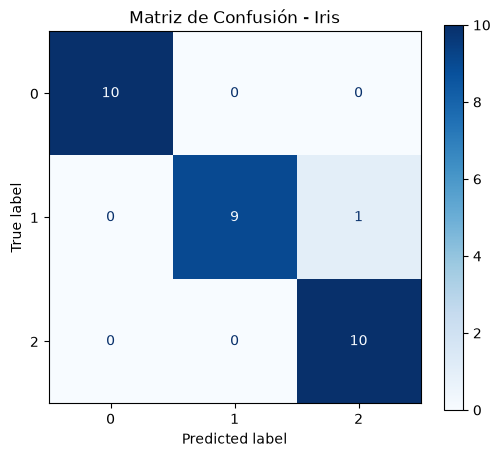

In [229]:
from sklearn.metrics import ConfusionMatrixDisplay
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(6, 5))

ConfusionMatrixDisplay.from_estimator(
    modelo, X_test, y_test, cmap="Blues", ax=ax
)

plt.title("Matriz de Confusión - Iris")
plt.show()


### Como identificamos TP, FP, FN

En Iris tenemos tres clases. Entonces, para calcular las métricas, elegimos una especie como positiva y consideramos a todas las demás negativas.
Por ejemplo, imaginemos que queremos evaluar específicamente qué tan bien reconoce el modelo a las flores Versicolor.
Nuestra clase positiva será 1 (Versicolor).
- TP: flores Versicolor que el modelo clasificó como Versicolor.
- FP: flores que no eran Versicolor, pero el modelo dijo que sí.
- FN: flores que eran Versicolor, pero el modelo las clasificó como otra especie.

En base a esto, los calculos son siempre lo mismo:

$\boxed{\text{Precisión} = \frac{\text{TP}}{\text{TP} + \text{FP}}}$
$Precision=\frac{9}{9+0}=1$

$\boxed{\text{Recall} = \frac{\text{TP}}{\text{TP} + \text{FN}}}$
$Recall=\frac{9}{9+1}=0.90$


Para calcular la precision, tengo que fijarme toda la columna. Para calcular recall, tengo que fijarme toda la fila

## 6. Precision, Recall y F1 por clase

In [230]:
from sklearn.metrics import accuracy_score

from sklearn.metrics import classification_report

print(classification_report(y_test, y_pred))

print("Accuracy entrenamiento:", accuracy_score(y_train, modelo.predict(X_train)))
print("Accuracy prueba:", accuracy_score(y_test, modelo.predict(X_test)))


              precision    recall  f1-score   support

           0       1.00      1.00      1.00        10
           1       1.00      0.90      0.95        10
           2       0.91      1.00      0.95        10

    accuracy                           0.97        30
   macro avg       0.97      0.97      0.97        30
weighted avg       0.97      0.97      0.97        30

Accuracy entrenamiento: 0.9833333333333333
Accuracy prueba: 0.9666666666666667


## 7. Promedios multiclase

### `Macro average`

Si necesitamos comparar dos modelos multiclase. Sería útil tener un valor que resuma el desempeño sobre las tres especies.

Para eso tenemos metricas como `Macro average`

Por ejemplo, en nuestro Iris:


|Clase|Recall|
|--|--|
|Setosa	|1.00|
|Versicolor	|0.90|
|Virginica	|1.00|

Entonces:

$Recall_{macro}=\frac{1+0.90+1}{3}=0.9667$

Cada especie aporta lo mismo al promedio, independientemente de cuántas observaciones tenga.

### `Weighted average`

Weighted avg también combina las métricas de las tres clases, pero les da un peso según su cantidad de observaciones reales (support).

|Clase|Recall|Support|
|--|--|--|
|Setosa|1.00|10|
|Versicolor|0.90|10|
|Virginica|1.00|10|


$Recall_{weighted}=\frac{1(10)+0.90(10)+1(10)}{10+10+10}$


$Recall_{weighted}=0.9667$

Nos dio exactamente lo mismo que Macro
¿Por qué? Porque nuestro dataset de prueba está perfectamente balanceado: tenemos 10 flores de cada especie.
Si tuviéramos muchas más flores de una especie que de otra, los promedios podrían ser diferentes.

### ¿Qué representa cada promedio?

|Métrica|Qué te dice|Cuándo prestarle atención|
|--|--|--|
|Macro F1|	Qué tan bien funciona el modelo, dando igual importancia a todas las clases.|	Cuando queremos que las tres clases se clasifiquen bien, incluso las menos frecuentes.|
|Weighted F1|	Qué tan bien funciona el modelo considerando la frecuencia de cada clase.|	Cuando queremos evaluar el rendimiento global teniendo en cuenta la distribución del dataset.|

Macro F1 sirve cuando quiero ver el rendimiento de todas las clases por igual.
Wighted F1 sirve para cuando quiero ver el rendimiento en general del modelo sin importar si el dataset esta balanceado o no

## Entrenamiento de otros modelos para comparar

In [231]:
modelo_2 = DecisionTreeClassifier(max_depth=10)

modelo_2.fit(X_train, y_train)




,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",10
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.",'gini'
,"splitter splitter: {""best"", ""random""}, default=""best""The strategy used to choose the split at each node. Supportedstrategies are ""best"" to choose the best split and ""random"" to choosethe best random split among considered features for this split.",'best'
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: int, float or {""sqrt"", ""log2""}, default=NoneThe number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`.Note: splitting may inspect more than ``max_features`` features ifneeded to find a valid split.",None
,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness of the estimator. The features are alwaysrandomly permuted at each split, even if ``splitter`` is set to``""best""``. When ``max_features < n_features``, the algorithm willselect ``max_features`` at random at each split before finding the bestsplit among them. But the best found split may vary across differentruns, even if ``max_features=n_features``. That is the case, if theimprovement of the criterion is identical for several splits and onesplit has to be selected at random. To obtain a deterministic behaviourduring fitting, ``random_state`` has to be fixed to an integer.See :term:`Glossary <random_state>` for details.",None
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow a tree with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samples

In [232]:
y_pred_2 = modelo_2.predict(X_test)

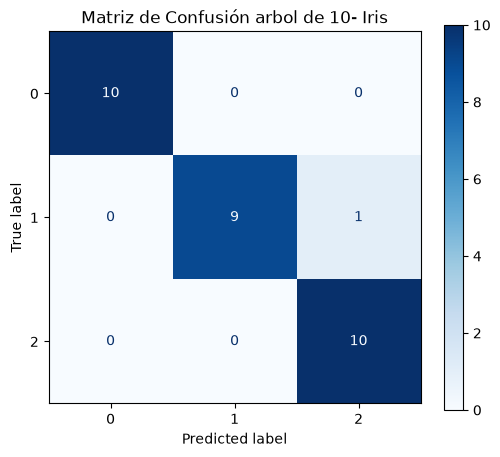

In [233]:
fig, ax = plt.subplots(figsize=(6, 5))

ConfusionMatrixDisplay.from_estimator(
    modelo_2, X_test, y_test, cmap="Blues", ax=ax
)

plt.title("Matriz de Confusión arbol de 10- Iris")
plt.show()

In [234]:
print(classification_report(y_test, y_pred_2))

print("Accuracy entrenamiento:", accuracy_score(y_train, modelo_2.predict(X_train)))
print("Accuracy prueba:", accuracy_score(y_test, modelo_2.predict(X_test)))

              precision    recall  f1-score   support

           0       1.00      1.00      1.00        10
           1       1.00      0.90      0.95        10
           2       0.91      1.00      0.95        10

    accuracy                           0.97        30
   macro avg       0.97      0.97      0.97        30
weighted avg       0.97      0.97      0.97        30

Accuracy entrenamiento: 1.0
Accuracy prueba: 0.9666666666666667


## Cross-Validation y Optimización de Hiperparámetros (Grid Search).

Ir entrenando uno a uno los modelos para ver que resultados son mejores es tedioso y encima nos estariamos guiando con los resultados que obtuvimos en el set de pruebas para tomar decisiones sobre que molelo ejegir.

Lo que hice hasta ahora fue comparar ambos modelos utilizando X_test, lo cual estuvo bien como ejercicio para estudiar sobreajuste.
Pero si empiezo a probar profundidades 2, 3, 4, 5, 6, 7... y me quedo con la que consigue el mejor resultado en X_test.

¿Cuál es el problema?

Aunque el árbol nunca se entrene directamente con X_test, sí estaria usando sus resultados para decidir qué hiperparámetros elegir.
Eso significa que estaria adaptando mis decisiones a las particularidades de ese conjunto de prueba.
Por eso hay que separar dos tareas:
- Seleccionar los hiperparámetros: hacerlo con datos de entrenamiento y validación.
- Evaluar el modelo elegido: hacerlo finalmente con datos de prueba que no usamos para tomar decisiones.

Para eso se usa cross validation

Con validación cruzada de cinco particiones (cv=5), tomamos las 120 flores de entrenamiento y las dividimos en cinco grupos de 24.
En cada iteración, cuatro grupos se utilizan para entrenar el árbol y uno para validarlo.

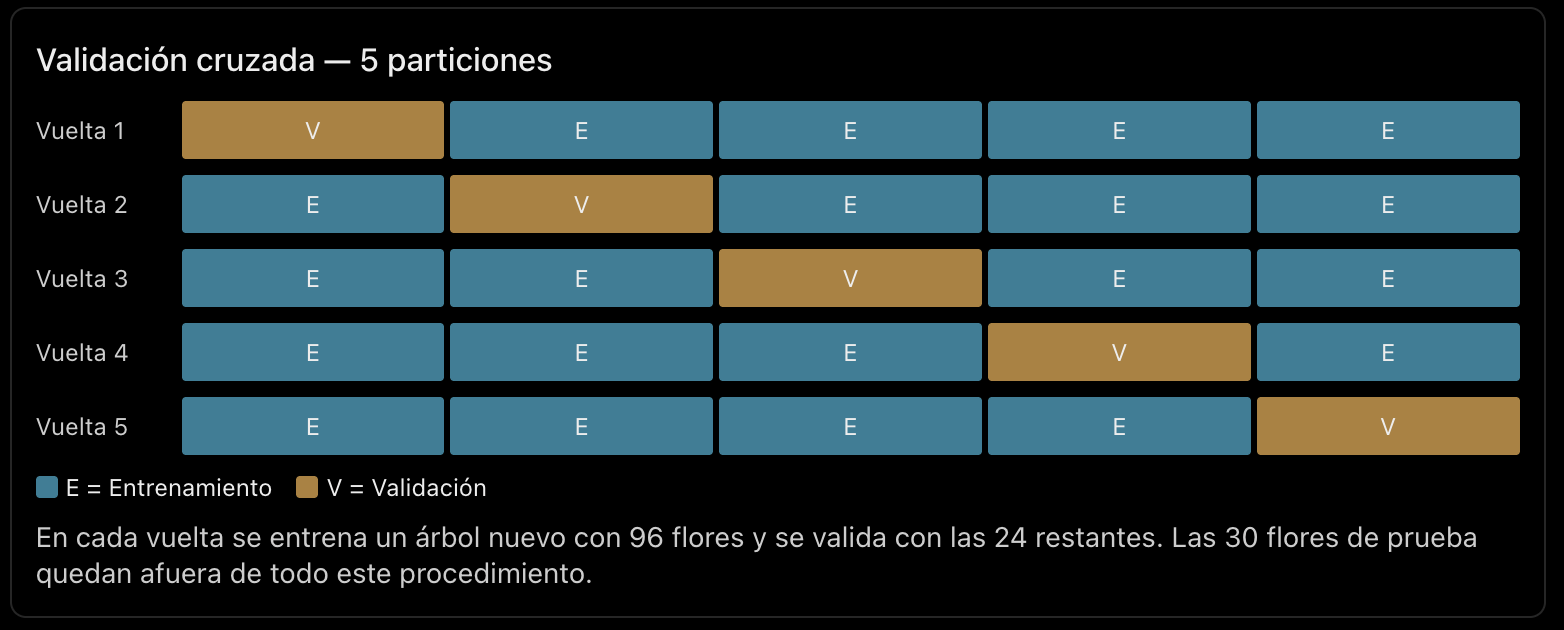

Esto permite obtener cinco resultados de validación para un mismo hiperparámetro. Después calculamos su promedio.

Ahora, diferencias que hay que tener en cuenta para las herramientas que hay que usar:
- GridSearchCV → busca la mejor configuración de hiperparámetros entre las que le indicamos. ¿Cuál de estas configuraciones funciona mejor?
- cross_val_score() → evalúa qué tan bien generaliza un modelo con una configuración determinada, utilizando distintos entrenamientos y validaciones. ¿Qué tan bien funciona esta configuración?

GridSearchCV selecciona la mejor configuración según los resultados de validación cruzada, no según X_test.

### GridSearchCV para obtener el mejor modelo segun rango de hiperparametros

In [235]:
from sklearn.model_selection import GridSearchCV

param_grid = {"max_depth": range(1, 16)}

grid = GridSearchCV(
    DecisionTreeClassifier(random_state=42),
    param_grid,
    cv=5
)

grid.fit(X_train, y_train)

,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",DecisionTreeC...ndom_state=42)
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'max_depth': range(1, 16)}"
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",5
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",None
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",None
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see how to design a custom selection strategy using a callablevia `refit`.See :ref:`this example<sphx_glr_auto_examples_model_selection_plot_grid_search_refit_callable.py>`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support for callable added.",True
,"verbose verbose: int, default=0Controls the verbosity of information printed during fitting, with hi

In [236]:
print("Mejores hiperparámetros:", grid.best_params_)
print("Mejor Accuracy promedio:", grid.best_score_)
print("Mejor modelo:", grid.best_estimator_)

Mejores hiperparámetros: {'max_depth': 4}
Mejor Accuracy promedio: 0.9416666666666668
Mejor modelo: DecisionTreeClassifier(max_depth=4, random_state=42)


### Construyo el mejor modelo segun lo que devolvio el grid search

In [237]:
mejor_modelo = grid.best_estimator_

y_pred_final = mejor_modelo.predict(X_test)

In [238]:
print("Accuracy:", accuracy_score(y_test, y_pred_final))
print(classification_report(y_test, y_pred_final))

Accuracy: 0.9333333333333333
              precision    recall  f1-score   support

           0       1.00      1.00      1.00        10
           1       0.90      0.90      0.90        10
           2       0.90      0.90      0.90        10

    accuracy                           0.93        30
   macro avg       0.93      0.93      0.93        30
weighted avg       0.93      0.93      0.93        30



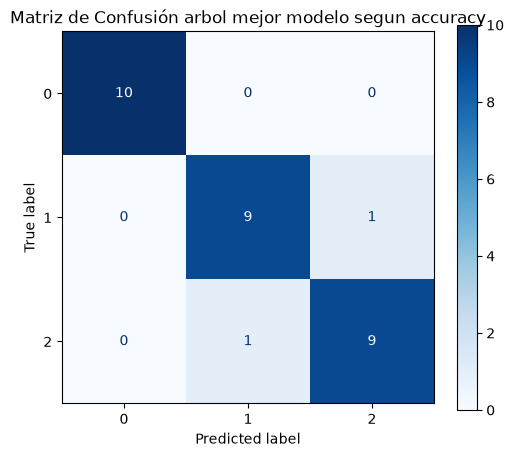

In [239]:
fig, ax = plt.subplots(figsize=(6, 5))

ConfusionMatrixDisplay.from_estimator(
    mejor_modelo, X_test, y_test, cmap="Blues", ax=ax
)

plt.title("Matriz de Confusión arbol mejor modelo segun accuracy")
plt.show()

### Buscando mejor configuracion según Macro F1

In [240]:
grid_f1 = GridSearchCV(
    DecisionTreeClassifier(random_state=42),
    param_grid,
    cv=5,
    scoring="f1_macro"
)

grid_f1.fit(X_train, y_train)

,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",DecisionTreeC...ndom_state=42)
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'max_depth': range(1, 16)}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",'f1_macro'
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",5
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",None
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see how to design a custom selection strategy using a callablevia `refit`.See :ref:`this example<sphx_glr_auto_examples_model_selection_plot_grid_search_refit_callable.py>`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support for callable added.",True
,"verbose verbose: int, default=0Controls the verbosity of information printed during fitting, w

In [241]:
print("Mejores hiperparámetros:", grid_f1.best_params_)
print("Mejor Macro F1 promedio:", grid_f1.best_score_)
print("Mejor modelo:", grid_f1.best_estimator_)

Mejores hiperparámetros: {'max_depth': 4}
Mejor Macro F1 promedio: 0.9413040771864303
Mejor modelo: DecisionTreeClassifier(max_depth=4, random_state=42)


In [242]:
modelo_f1 = grid_f1.best_estimator_

y_pred_f1 = modelo_f1.predict(X_test)

print("Accuracy:", accuracy_score(y_test, y_pred_f1))
print(classification_report(y_test, y_pred_f1))

Accuracy: 0.9333333333333333
              precision    recall  f1-score   support

           0       1.00      1.00      1.00        10
           1       0.90      0.90      0.90        10
           2       0.90      0.90      0.90        10

    accuracy                           0.93        30
   macro avg       0.93      0.93      0.93        30
weighted avg       0.93      0.93      0.93        30



Me devolvio lo mismo jaja

## 8. Conclusiones

**Actividad final:** sintetizá qué aprendiste, qué clases identifica mejor el modelo y por qué no alcanza con mirar solo Accuracy.

In [243]:
# Podés escribir conclusiones en una celda Markdown adicional
